# 🎬 IMDb Movie Review Sentiment Analysis

**Business context.** Film Junky Union wants to automatically classify IMDb movie reviews as positive or negative, with a target test F1 score of at least **0.85**. This notebook explores sentiment distributions, text preprocessing, TF-IDF classifiers, and an exploratory BERT embedding experiment on a small sample. The provided training and test partitions are preserved.

## 1. Setup and Imports

In [1]:
import math

import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from tqdm.auto import tqdm

In [2]:
%matplotlib inline
%config InlineBackend.figure_format = 'png'
# Improve plot rendering on high-density displays
%config InlineBackend.figure_format = 'retina'

plt.style.use('seaborn-v0_8' if 'seaborn-v0_8' in plt.style.available else 'ggplot')

In [3]:
# Enable progress_apply for pandas operations
tqdm.pandas()

## 2. Load the Dataset

In [4]:
from pathlib import Path

# Dataset is distributed in four TSV files to support browser-based GitHub uploads.
data_dir = Path('../data')
parts = [data_dir / f'imdb_reviews_part_{i}.tsv' for i in range(1, 5)]
missing_parts = [str(path) for path in parts if not path.is_file()]
if missing_parts:
    raise FileNotFoundError(f'Missing dataset files: {missing_parts}')

df_reviews = pd.concat(
    [pd.read_csv(path, sep='\t', dtype={'votes': 'Int64'}) for path in parts],
    ignore_index=True
)
assert len(df_reviews) == 47331, 'Unexpected number of reviews after combining dataset parts.'


In [5]:
print('Dataset shape:', df_reviews.shape)

Dimensões do conjunto de dados: (47331, 17)


In [6]:
display(df_reviews.head())

,tconst,title_type,primary_title,original_title,start_year,end_year,runtime_minutes,is_adult,genres,average_rating,votes,review,rating,sp,pos,ds_part,idx
0,tt0068152,movie,$,$,1971,\N,121,0,"Comedy,Crime,Drama",6.3,2218,The pakage implies that Warren Beatty and Gold...,1,neg,0,train,8335
1,tt0068152,movie,$,$,1971,\N,121,0,"Comedy,Crime,Drama",6.3,2218,How the hell did they get this made?! Presenti...,1,neg,0,train,8336
2,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,There is no real story the film seems more lik...,3,neg,0,test,2489
3,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,Um .... a serious film about troubled teens in...,7,pos,1,test,9280
4,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,I'm totally agree with GarryJohal from Singapo...,9,pos,1,test,9281


In [7]:
print('\nInformações gerais:')
df_reviews.info()


Informações gerais:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47331 entries, 0 to 47330
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   tconst           47331 non-null  object 
 1   title_type       47331 non-null  object 
 2   primary_title    47331 non-null  object 
 3   original_title   47331 non-null  object 
 4   start_year       47331 non-null  int64  
 5   end_year         47331 non-null  object 
 6   runtime_minutes  47331 non-null  object 
 7   is_adult         47331 non-null  int64  
 8   genres           47331 non-null  object 
 9   average_rating   47329 non-null  float64
 10  votes            47329 non-null  Int64  
 11  review           47331 non-null  object 
 12  rating           47331 non-null  int64  
 13  sp               47331 non-null  object 
 14  pos              47331 non-null  int64  
 15  ds_part          47331 non-null  object 
 16  idx              47331 non-null  int6

The dataset contains 47,331 reviews and 17 columns. The main fields (`review`, `pos`, and `ds_part`) have no missing values. Only `average_rating` and `votes` contain two missing values in total; these fields are not used for sentiment classification.

In [8]:
# Check data quality
print('Fully duplicated rows:', df_reviews.duplicated().sum())

print('\nRepeated review texts:', df_reviews['review'].duplicated().sum())

print('\nClass distribution:')
print(df_reviews['pos'].value_counts())

print('\nClass percentages:')
print(df_reviews['pos'].value_counts(normalize=True) * 100)

print('\nTrain/test partition sizes:')
print(df_reviews['ds_part'].value_counts())

Registros duplicados: 0

Resenhas duplicadas: 91

Distribuição das classes:
0    23715
1    23616
Name: pos, dtype: int64

Distribuição percentual:
0    50.104583
1    49.895417
Name: pos, dtype: float64

Distribuição entre treinamento e teste:
train    23796
test     23535
Name: ds_part, dtype: int64


No fully duplicated records were found, although 91 review texts are repeated. These are retained to preserve the original dataset. The labels are nearly balanced (50.10% negative and 49.90% positive), so no class rebalancing is needed. The provided partitions contain 23,796 training and 23,535 test reviews.

## 3. Exploratory Data Analysis

Explore the distribution of films and reviews across release years.

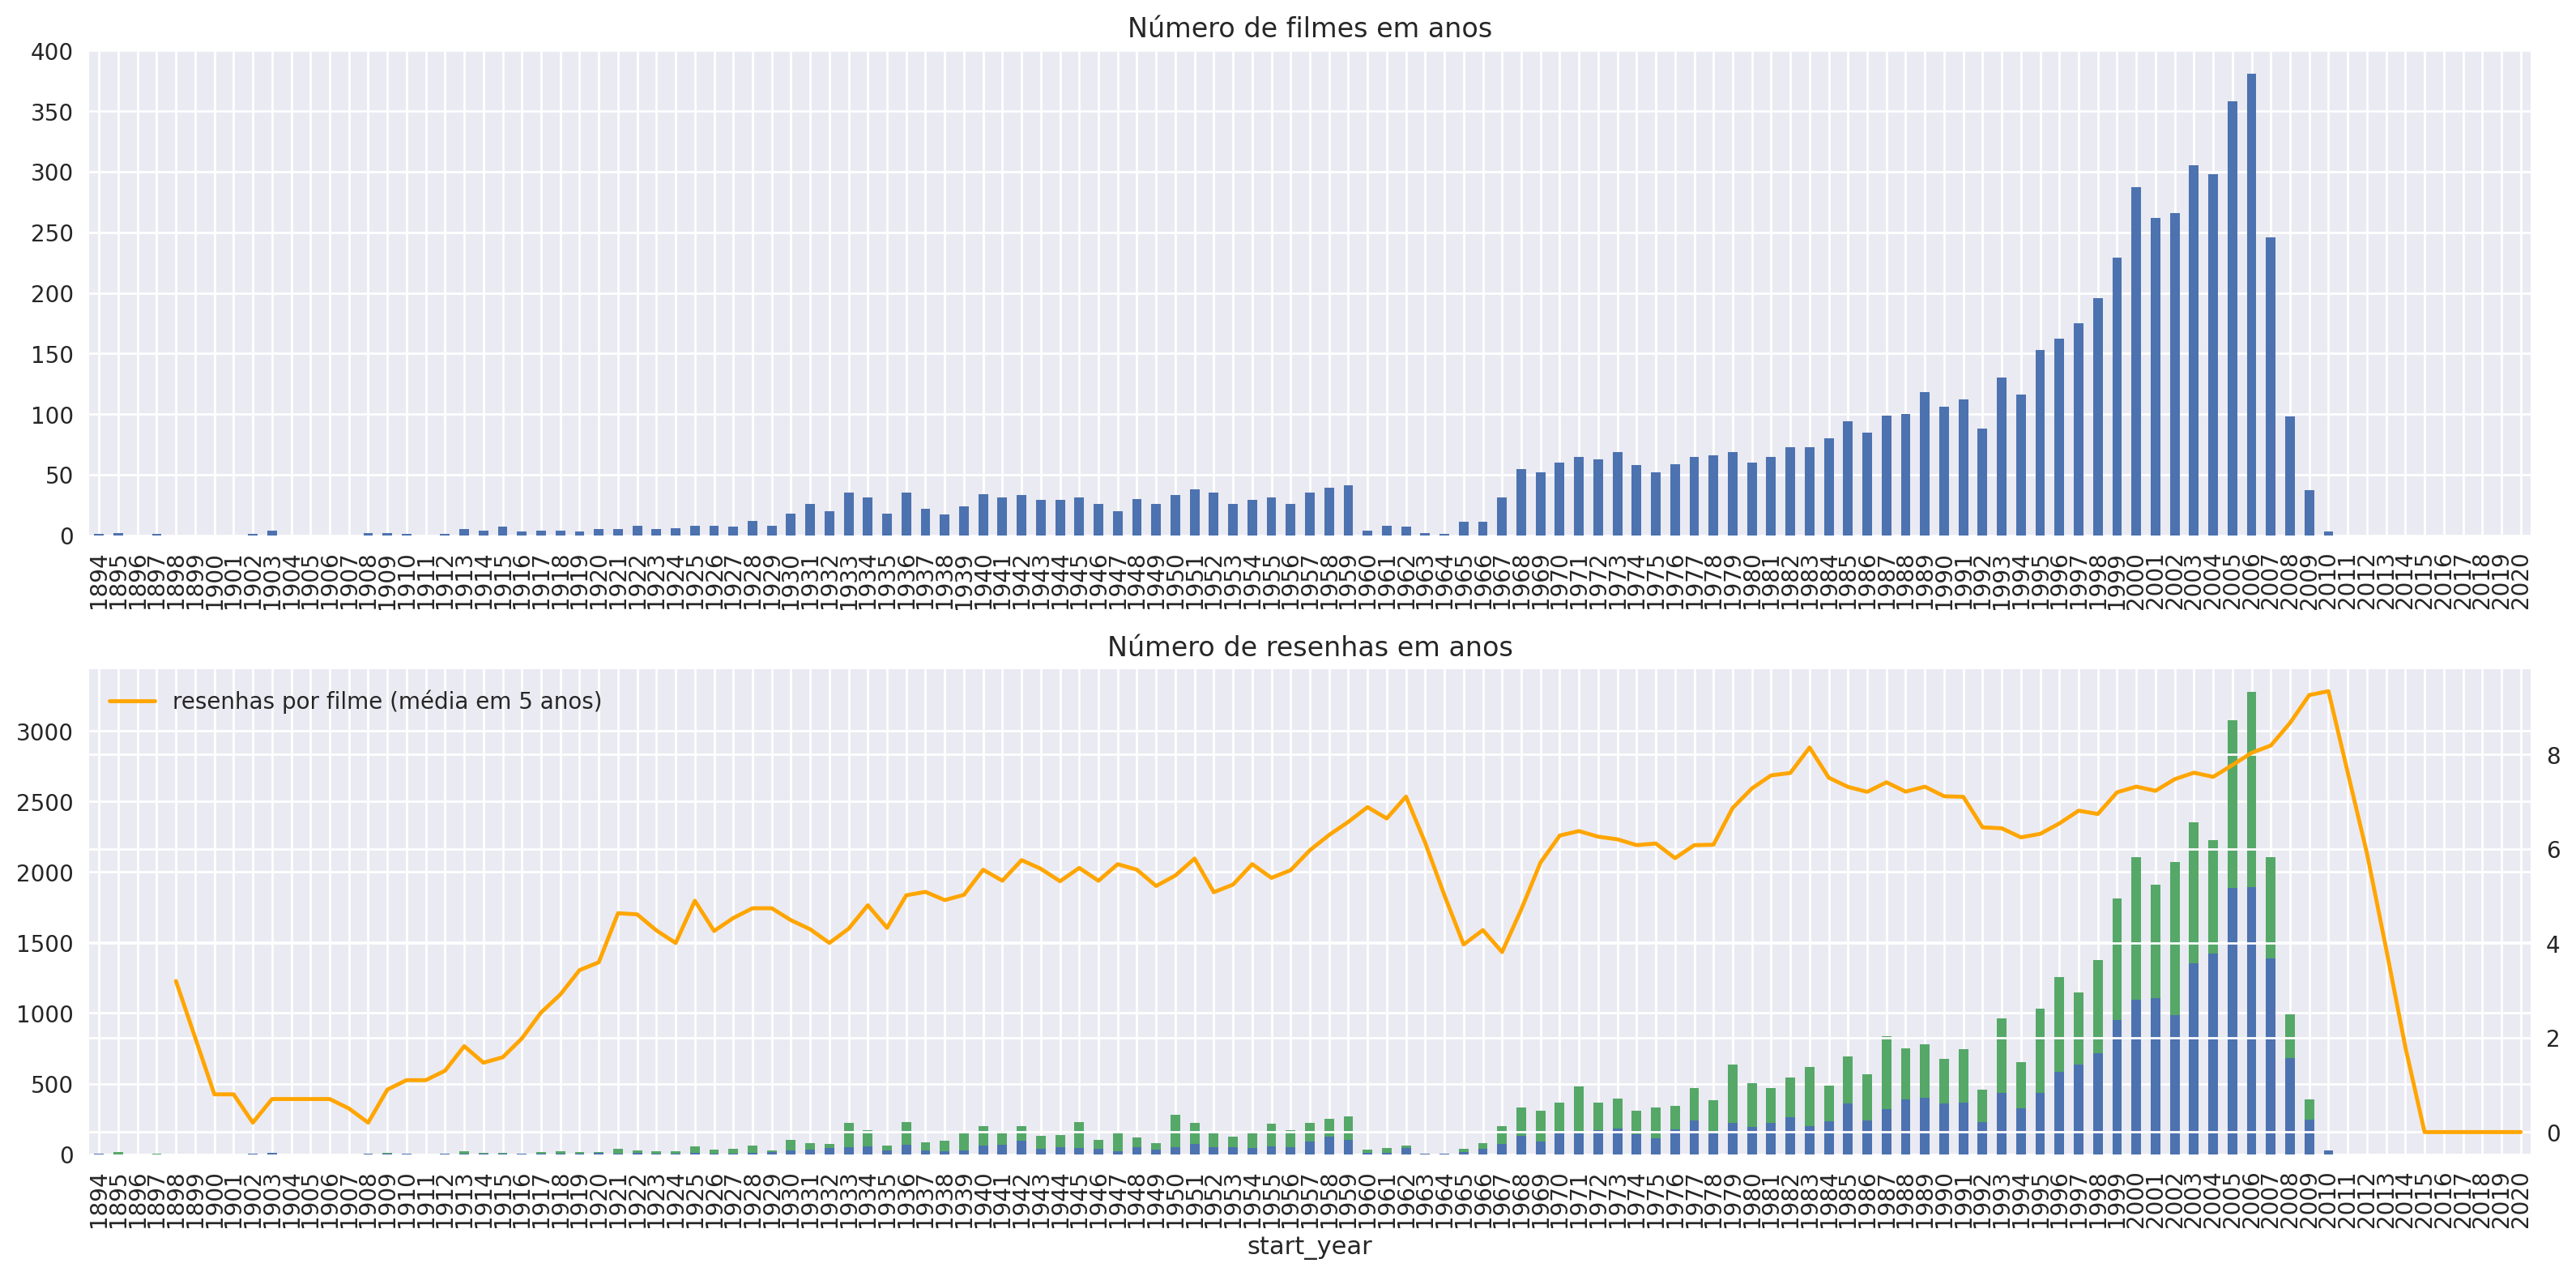

In [9]:

fig, axs = plt.subplots(2, 1, figsize=(16, 8))

ax = axs[0]

dft1 = df_reviews[['tconst', 'start_year']].drop_duplicates() \
    ['start_year'].value_counts().sort_index()
dft1 = dft1.reindex(index=np.arange(dft1.index.min(), max(dft1.index.max(), 2021))).fillna(0)
dft1.plot(kind='bar', ax=ax)
ax.set_title('Número de filmes em anos')

ax = axs[1]

dft2 = df_reviews.groupby(['start_year', 'pos'])['pos'].count().unstack()
dft2 = dft2.reindex(index=np.arange(dft2.index.min(), max(dft2.index.max(), 2021))).fillna(0)

dft2.plot(kind='bar', stacked=True, label='#reviews (neg, pos)', ax=ax)

dft2 = df_reviews['start_year'].value_counts().sort_index()
dft2 = dft2.reindex(index=np.arange(dft2.index.min(), max(dft2.index.max(), 2021))).fillna(0)
dft3 = (dft2/dft1).fillna(0)
axt = ax.twinx()
dft3.reset_index(drop=True).rolling(5).mean().plot(color='orange', label='resenhas por filme (média em 5 anos)', ax=axt)

lines, labels = axt.get_legend_handles_labels()
ax.legend(lines, labels, loc='upper left')

ax.set_title('Número de resenhas em anos')

fig.tight_layout()

Inspect the distribution of the number of reviews per film using counts and a density estimate.

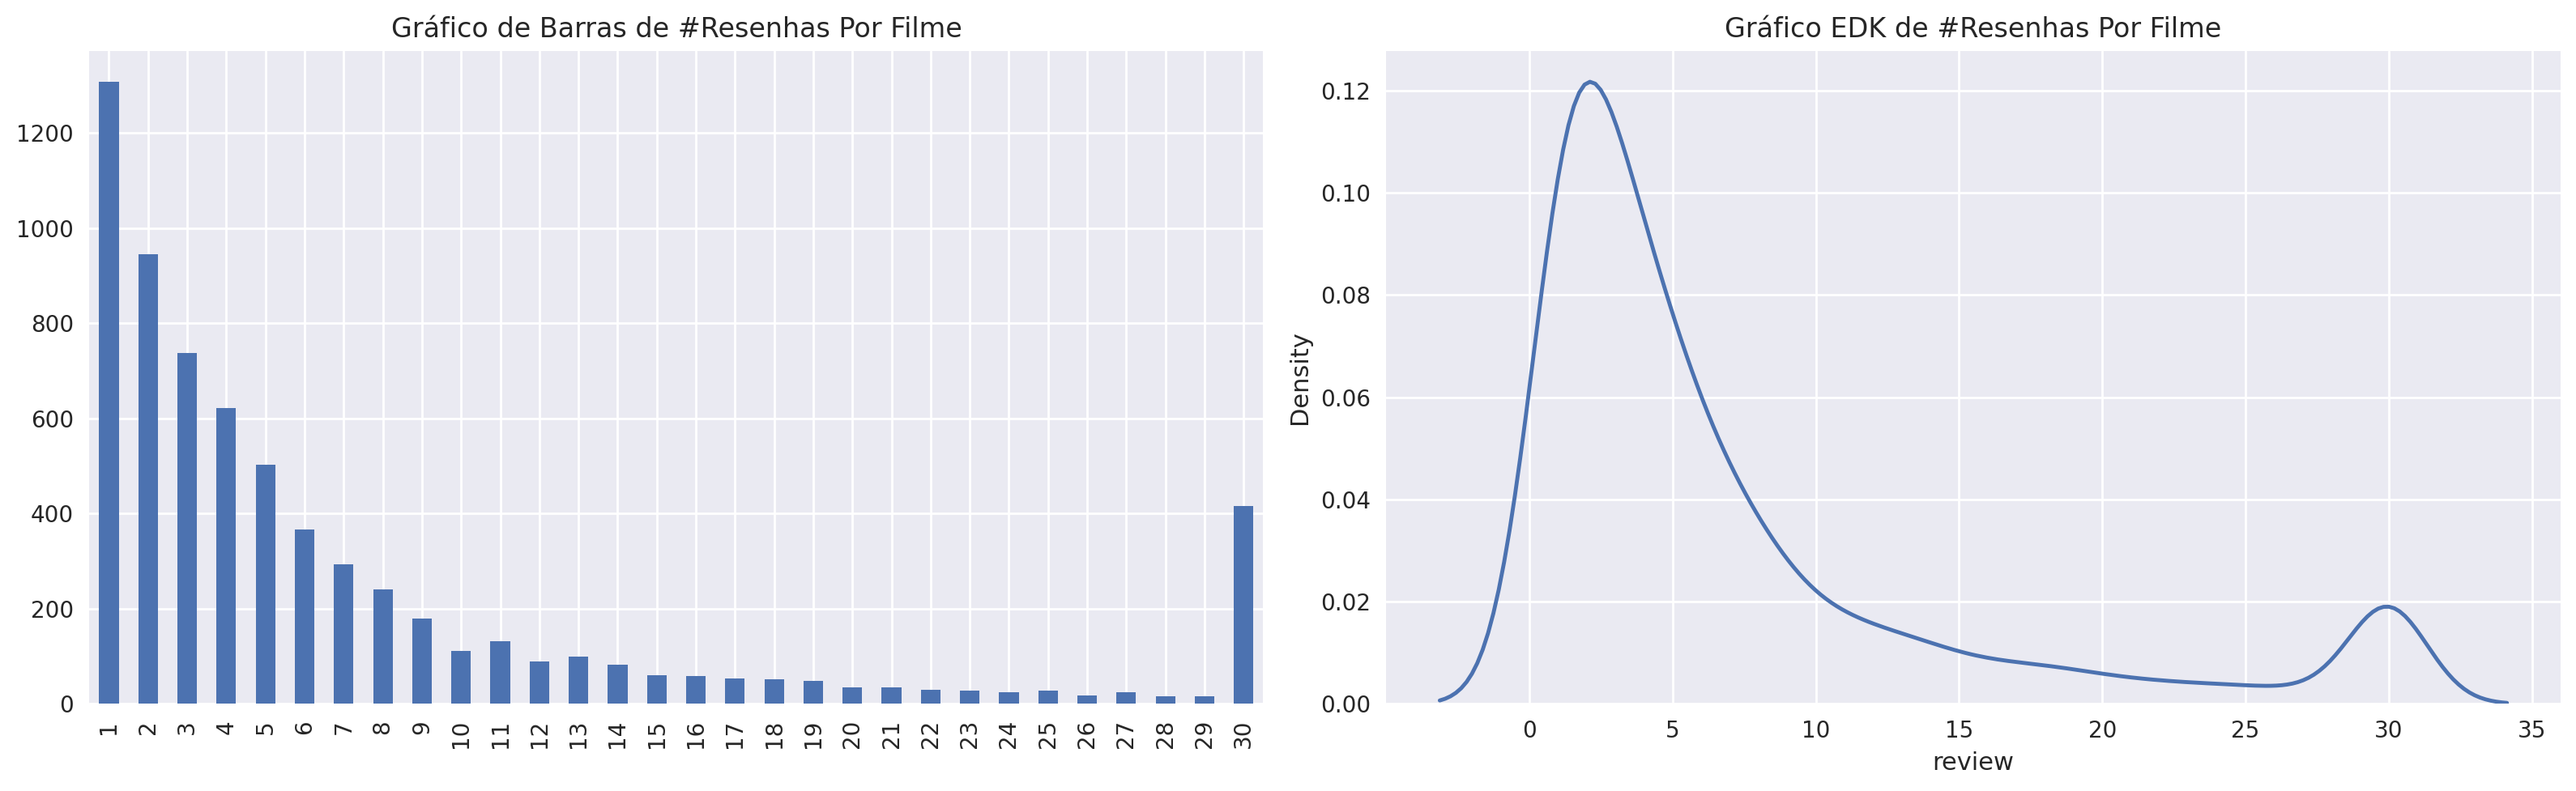

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5))

ax = axs[0]
dft = df_reviews.groupby('tconst')['review'].count() \
    .value_counts() \
    .sort_index()
dft.plot.bar(ax=ax)
ax.set_title('Gráfico de Barras de #Resenhas Por Filme')

ax = axs[1]
dft = df_reviews.groupby('tconst')['review'].count()
sns.kdeplot(dft, ax=ax)
ax.set_title('Gráfico EDK de #Resenhas Por Filme')

fig.tight_layout()

Most films and reviews are concentrated in the 2000s. Older films have fewer observations, and the number of reviews per film is right-skewed; most films have relatively few reviews.

In [11]:
df_reviews['pos'].value_counts()

0    23715
1    23616
Name: pos, dtype: int64

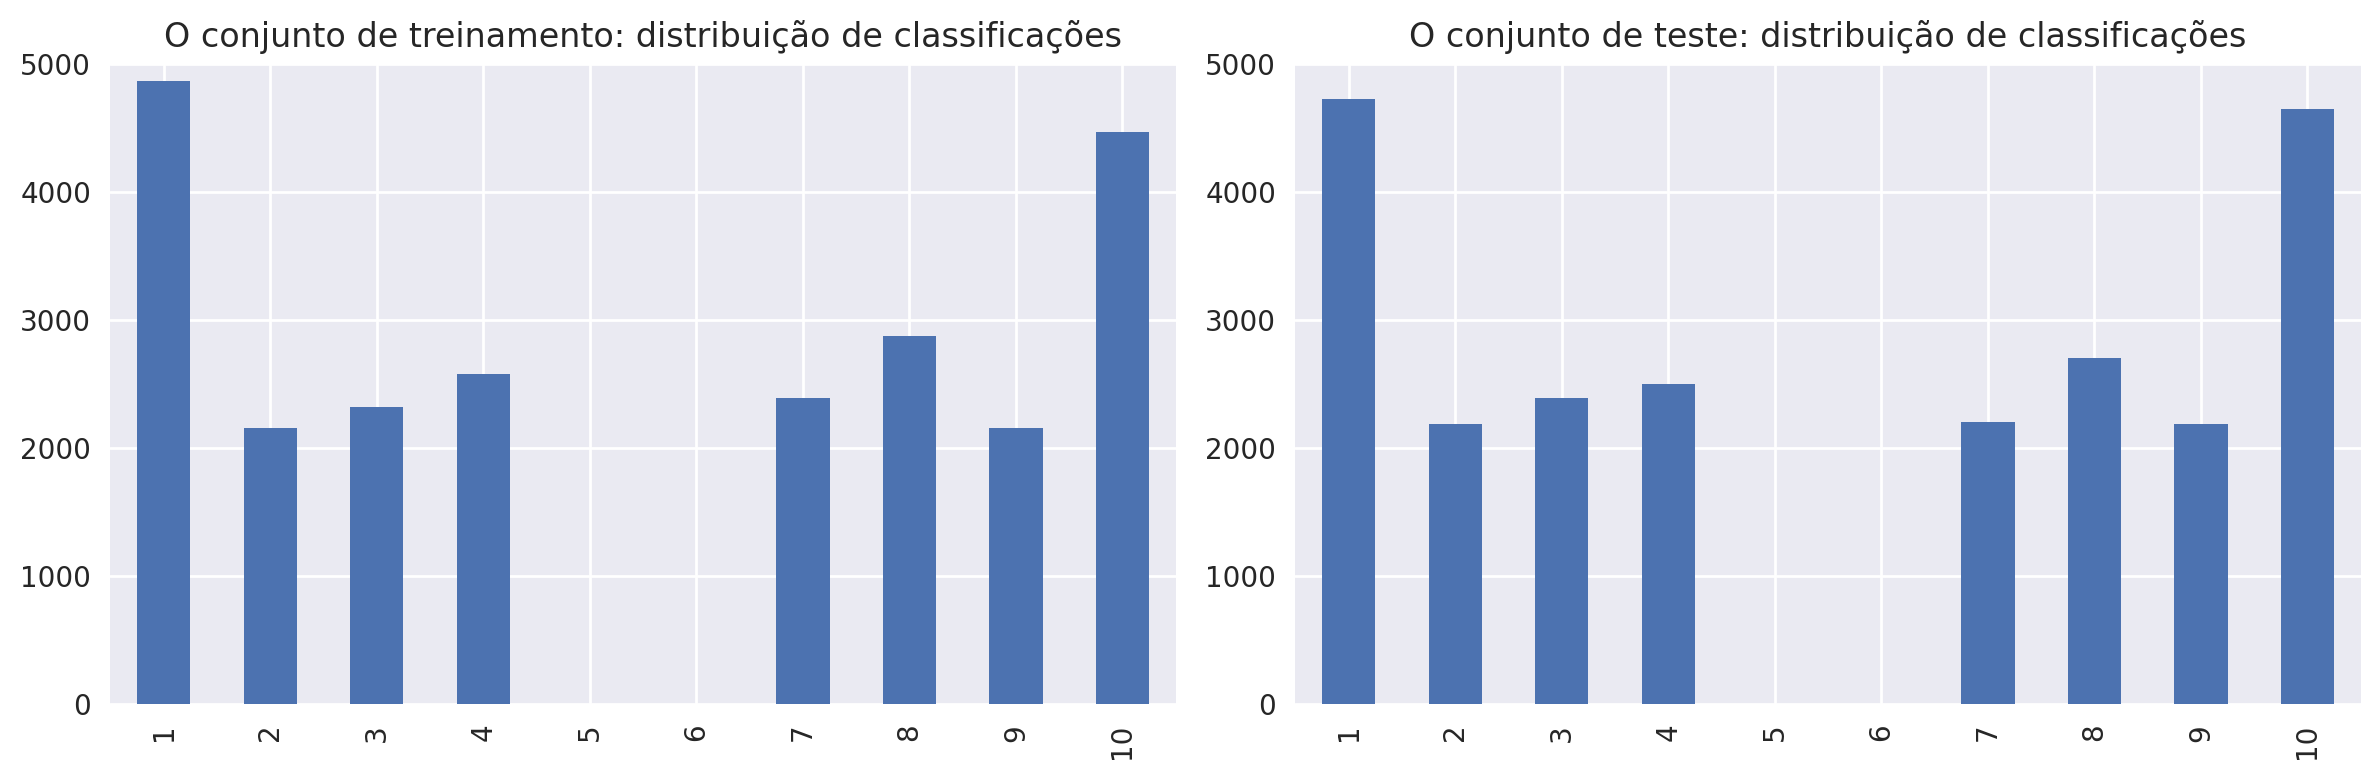

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

ax = axs[0]
dft = df_reviews.query('ds_part == "train"')['rating'].value_counts().sort_index()
dft = dft.reindex(index=np.arange(min(dft.index.min(), 1), max(dft.index.max(), 11))).fillna(0)
dft.plot.bar(ax=ax)
ax.set_ylim([0, 5000])
ax.set_title('O conjunto de treinamento: distribuição de classificações')

ax = axs[1]
dft = df_reviews.query('ds_part == "test"')['rating'].value_counts().sort_index()
dft = dft.reindex(index=np.arange(min(dft.index.min(), 1), max(dft.index.max(), 11))).fillna(0)
dft.plot.bar(ax=ax)
ax.set_ylim([0, 5000])
ax.set_title('O conjunto de teste: distribuição de classificações')

fig.tight_layout()

Training and test sets show similar rating distributions, with many ratings at the extremes (1 and 10). Ratings of 5 and 6 are absent, reflecting the separation between negative and positive review labels.

Examine positive and negative reviews across years in the training and test partitions.

/.venv/lib/python3.9/site-packages/seaborn/distributions.py:1666: UserWarning: Support for alternate kernels has been removed. Using Gaussian kernel.
  warnings.warn(msg, UserWarning)
/.venv/lib/python3.9/site-packages/seaborn/distributions.py:1666: UserWarning: Support for alternate kernels has been removed. Using Gaussian kernel.
  warnings.warn(msg, UserWarning)
/.venv/lib/python3.9/site-packages/seaborn/distributions.py:1666: UserWarning: Support for alternate kernels has been removed. Using Gaussian kernel.
  warnings.warn(msg, UserWarning)
/.venv/lib/python3.9/site-packages/seaborn/distributions.py:1666: UserWarning: Support for alternate kernels has been removed. Using Gaussian kernel.
  warnings.warn(msg, UserWarning)


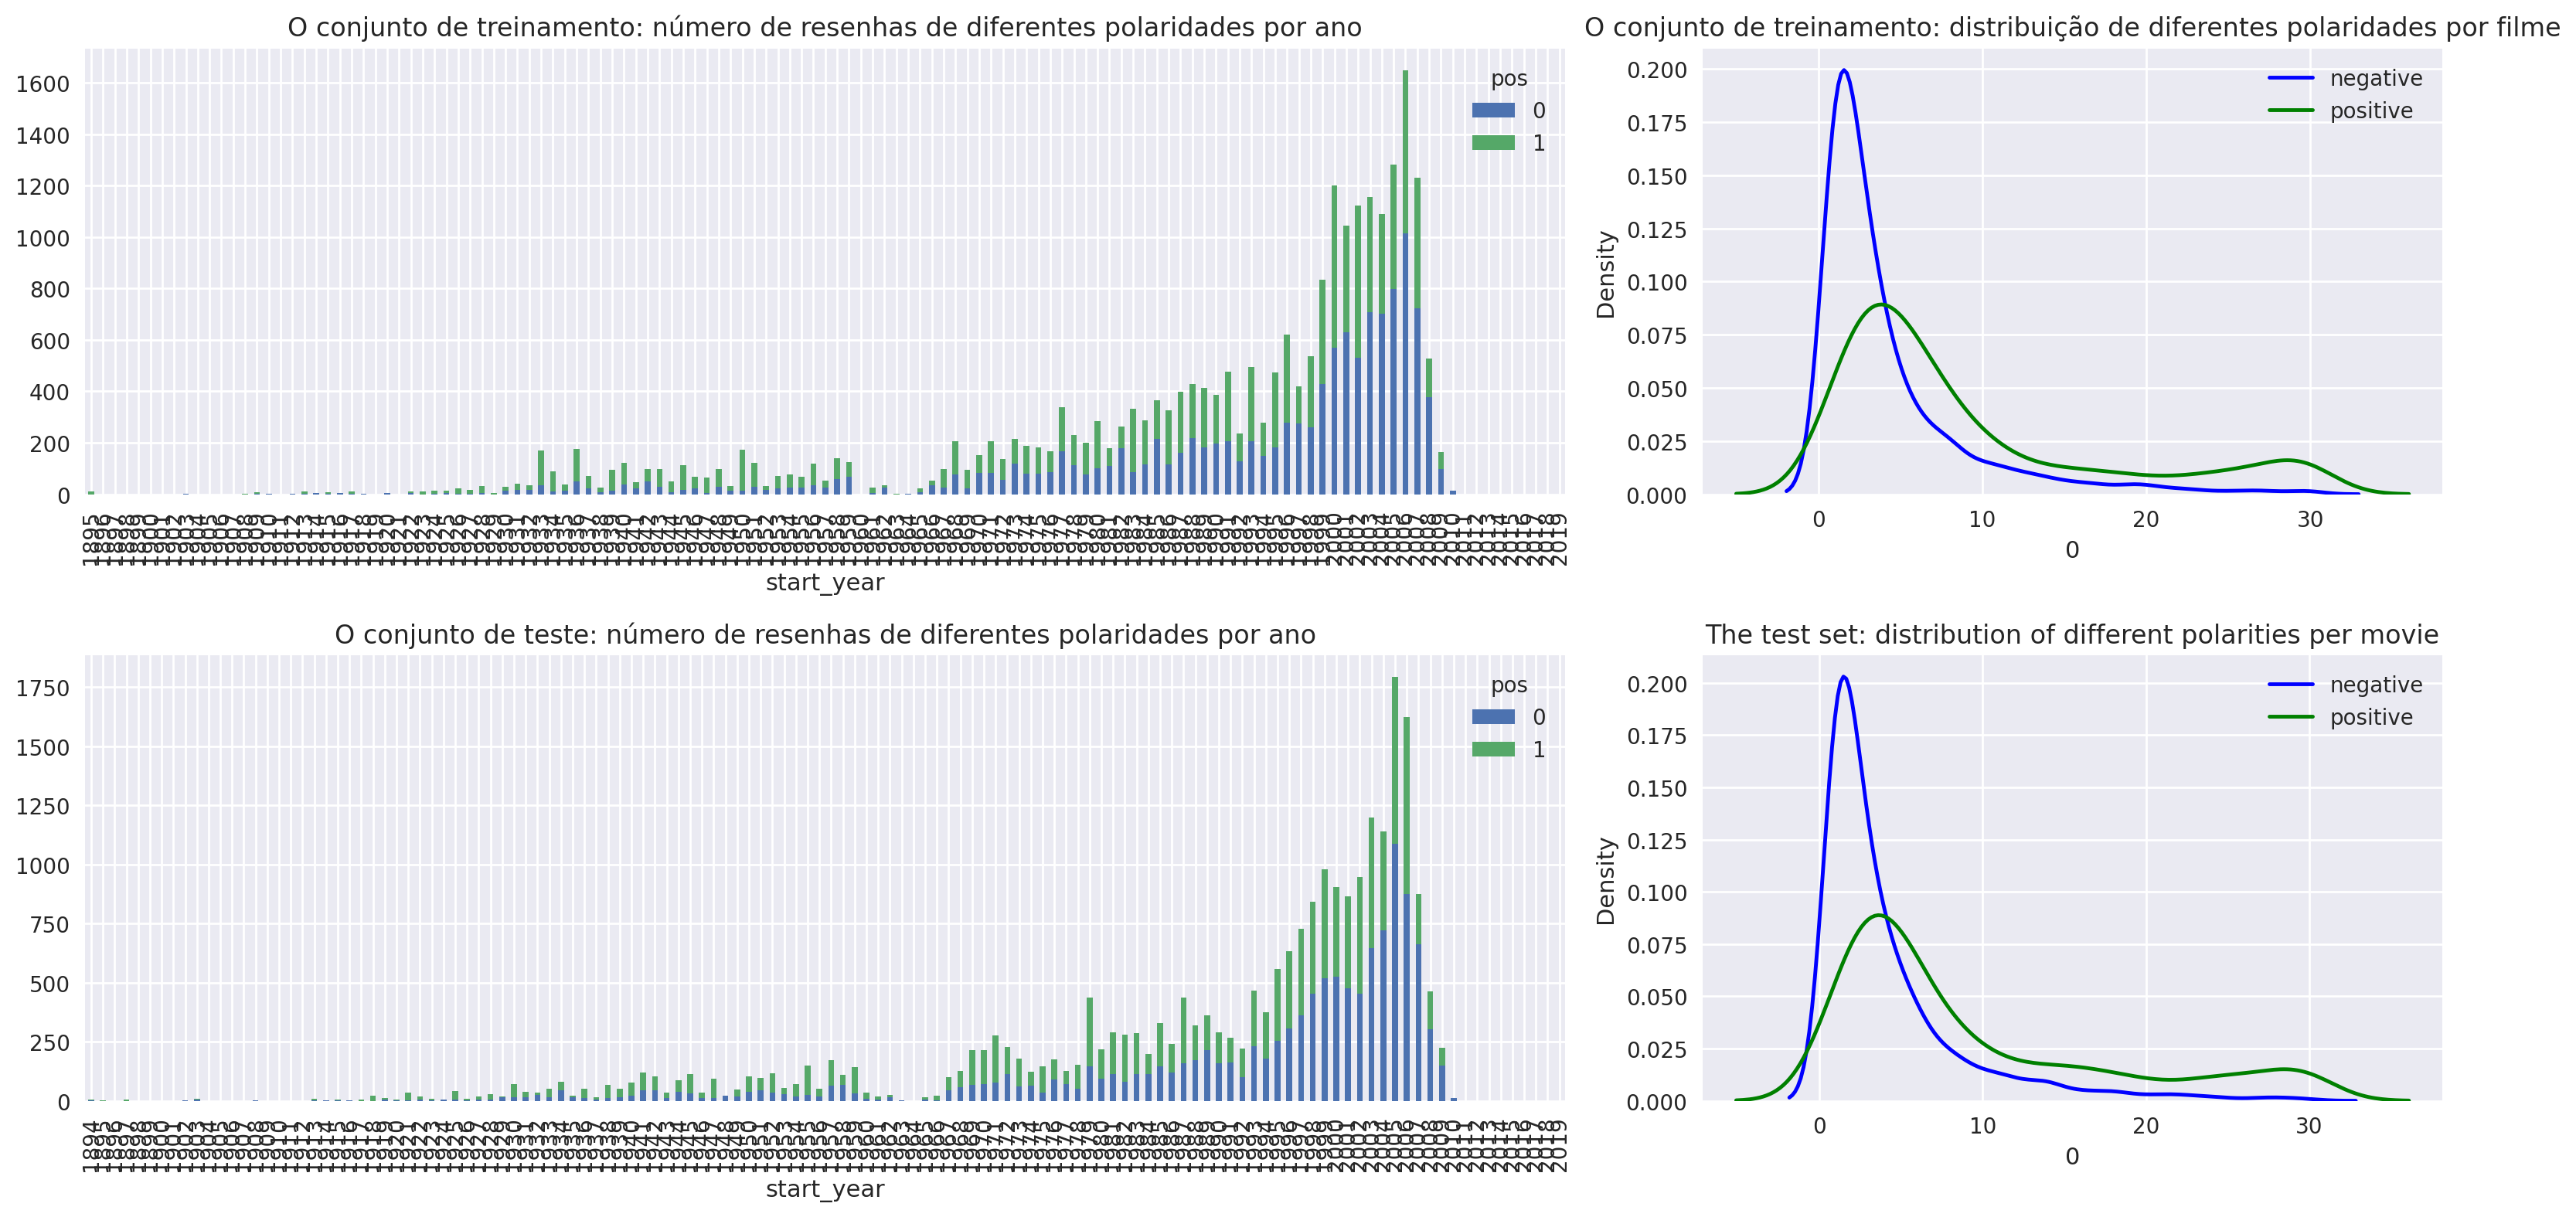

In [13]:

fig, axs = plt.subplots(2, 2, figsize=(16, 8), gridspec_kw=dict(width_ratios=(2, 1), height_ratios=(1, 1)))

ax = axs[0][0]

dft = df_reviews.query('ds_part == "train"').groupby(['start_year', 'pos'])['pos'].count().unstack()
dft.index = dft.index.astype('int')
dft = dft.reindex(index=np.arange(dft.index.min(), max(dft.index.max(), 2020))).fillna(0)
dft.plot(kind='bar', stacked=True, ax=ax)
ax.set_title('O conjunto de treinamento: número de resenhas de diferentes polaridades por ano')

ax = axs[0][1]

dft = df_reviews.query('ds_part == "train"').groupby(['tconst', 'pos'])['pos'].count().unstack()
sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
ax.legend()
ax.set_title('O conjunto de treinamento: distribuição de diferentes polaridades por filme')

ax = axs[1][0]

dft = df_reviews.query('ds_part == "test"').groupby(['start_year', 'pos'])['pos'].count().unstack()
dft.index = dft.index.astype('int')
dft = dft.reindex(index=np.arange(dft.index.min(), max(dft.index.max(), 2020))).fillna(0)
dft.plot(kind='bar', stacked=True, ax=ax)
ax.set_title('O conjunto de teste: número de resenhas de diferentes polaridades por ano')

ax = axs[1][1]

dft = df_reviews.query('ds_part == "test"').groupby(['tconst', 'pos'])['pos'].count().unstack()
sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
ax.legend()
ax.set_title('The test set: distribution of different polarities per movie')

fig.tight_layout()


Both partitions have similar positive and negative sentiment distributions, particularly for films released in the 2000s. Class balance is sufficiently close that resampling is unnecessary.

## 4. Evaluation Framework

Define a reusable evaluation routine for scikit-learn-compatible classifiers. The charts compare F1 across probability thresholds, ROC curves, and precision–recall curves.

In [14]:
import sklearn.metrics as metrics

def evaluate_model(model, train_features, train_target, test_features, test_target):

    eval_stats = {}

    fig, axs = plt.subplots(1, 3, figsize=(20, 6)) 

    for split, features, target in (('train', train_features, train_target), ('test', test_features, test_target)):

        eval_stats[split] = {}

        pred_target = model.predict(features)
        pred_proba = model.predict_proba(features)[:, 1]

        # F1
        f1_thresholds = np.arange(0, 1.01, 0.05)
        f1_scores = [metrics.f1_score(target, pred_proba>=threshold) for threshold in f1_thresholds]

        # ROC
        fpr, tpr, roc_thresholds = metrics.roc_curve(target, pred_proba)
        roc_auc = metrics.roc_auc_score(target, pred_proba)    
        eval_stats[split]['ROC AUC'] = roc_auc

        # Precision-recall curve
        precision, recall, pr_thresholds = metrics.precision_recall_curve(target, pred_proba)
        aps = metrics.average_precision_score(target, pred_proba)
        eval_stats[split]['APS'] = aps

        if split == 'train':
            color = 'blue'
        else:
            color = 'green'

        # F1 score
        ax = axs[0]
        max_f1_score_idx = np.argmax(f1_scores)
        ax.plot(f1_thresholds, f1_scores, color=color, label=f'{split}, max={f1_scores[max_f1_score_idx]:.2f} @ {f1_thresholds[max_f1_score_idx]:.2f}')
        # Highlight selected decision thresholds
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(f1_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(f1_thresholds[closest_value_idx], f1_scores[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.set_xlim([-0.02, 1.02])    
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('threshold')
        ax.set_ylabel('F1')
        ax.legend(loc='lower center')
        ax.set_title(f'F1 Score') 

        # ROC
        ax = axs[1]    
        ax.plot(fpr, tpr, color=color, label=f'{split}, ROC AUC={roc_auc:.2f}')
        # setting crosses for some thresholds
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(roc_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'            
            ax.plot(fpr[closest_value_idx], tpr[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.plot([0, 1], [0, 1], color='grey', linestyle='--')
        ax.set_xlim([-0.02, 1.02])    
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('FPR')
        ax.set_ylabel('TPR')
        ax.legend(loc='lower center')        
        ax.set_title(f'ROC Curve')

        # Precision-recall curve
        ax = axs[2]
        ax.plot(recall, precision, color=color, label=f'{split}, AP={aps:.2f}')
        # Highlight selected decision thresholds
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(pr_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(recall[closest_value_idx], precision[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.set_xlim([-0.02, 1.02])    
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('recall')
        ax.set_ylabel('precision')
        ax.legend(loc='lower center')
        ax.set_title(f'PRC')        

        eval_stats[split]['Accuracy'] = metrics.accuracy_score(target, pred_target)
        eval_stats[split]['F1'] = metrics.f1_score(target, pred_target, zero_division=0)

    df_eval_stats = pd.DataFrame(eval_stats)
    df_eval_stats = df_eval_stats.round(2)
    df_eval_stats = df_eval_stats.reindex(index=('Accuracy', 'F1', 'APS', 'ROC AUC'))

    print(df_eval_stats)

    return

## 5. Text Normalization

Normalize review text to lowercase alphabetic tokens before feature extraction.

In [15]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z]', ' ', text)
    return ' '.join(text.split())

df_reviews['review_norm'] = df_reviews['review'].apply(clean_text)

display(df_reviews[['review', 'review_norm']].head())

,review,review_norm
0,The pakage implies that Warren Beatty and Gold...,the pakage implies that warren beatty and gold...
1,How the hell did they get this made?! Presenti...,how the hell did they get this made presenting...
2,There is no real story the film seems more lik...,there is no real story the film seems more lik...
3,Um .... a serious film about troubled teens in...,um a serious film about troubled teens in sing...
4,I'm totally agree with GarryJohal from Singapo...,i m totally agree with garryjohal from singapo...


Reviews are lowercased and stripped of digits, punctuation, and other non-alphabetic characters. The normalized text is stored in `review_norm`.

## 6. Train/Test Partitions

Use the original dataset partitions provided by `ds_part` to avoid changing the evaluation protocol.

In [16]:
df_reviews_train = df_reviews.query('ds_part == "train"').copy()
df_reviews_test = df_reviews.query('ds_part == "test"').copy()

train_target = df_reviews_train['pos']
test_target = df_reviews_test['pos']

print(df_reviews_train.shape)
print(df_reviews_test.shape)

(23796, 18)
(23535, 18)


## 7. Sentiment Classification Models

### 7.1 Constant Baseline

In [17]:
from sklearn.dummy import DummyClassifier

          train  test
Acurácia    0.5   0.5
F1          0.0   0.0
APS         0.5   0.5
ROC AUC     0.5   0.5


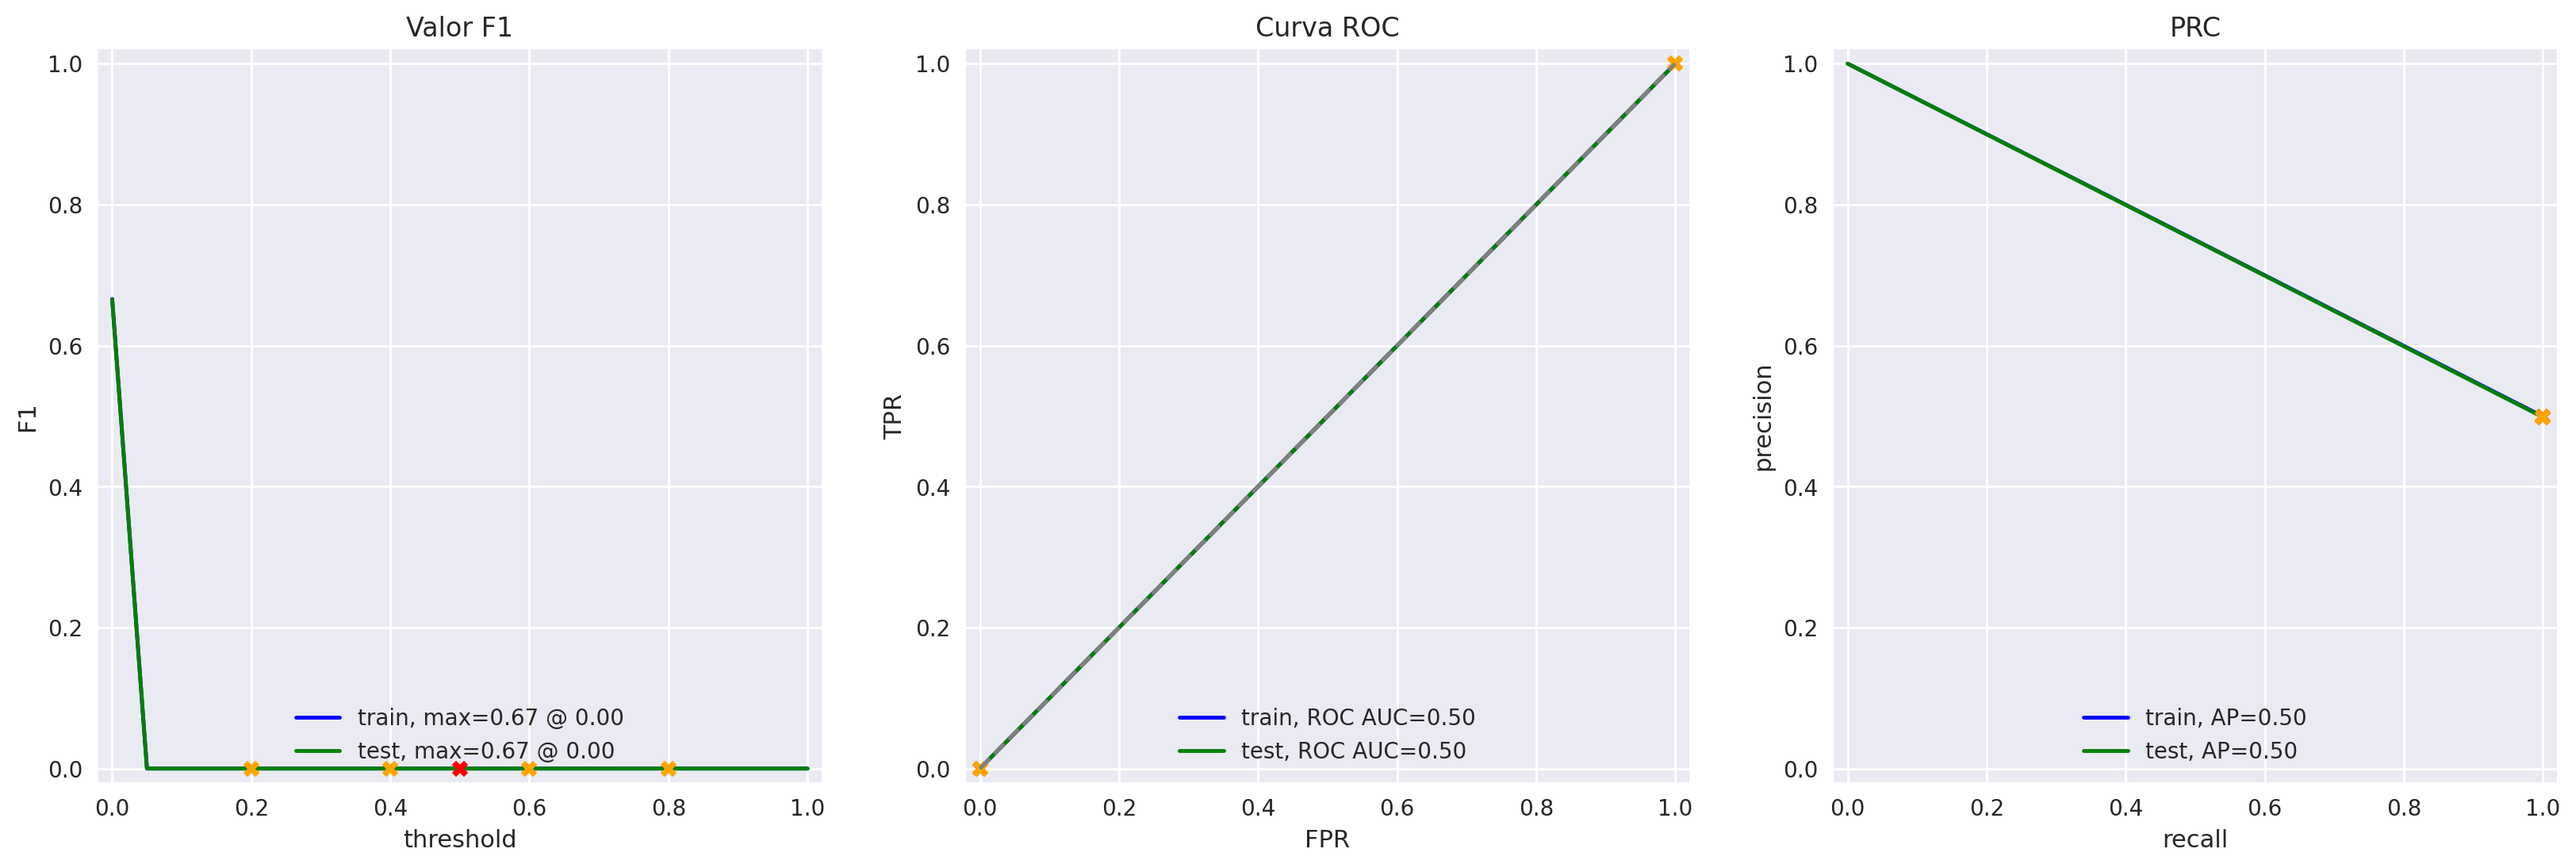

In [18]:
model_0 = DummyClassifier(strategy='most_frequent')

model_0.fit(
    df_reviews_train[['review_norm']],
    train_target
)

evaluate_model(
    model_0,
    df_reviews_train[['review_norm']],
    train_target,
    df_reviews_test[['review_norm']],
    test_target
)

The constant classifier yields ROC-AUC and average precision around 0.50, showing no useful discrimination. It provides a baseline for the trained models.

### 7.2 NLTK + TF-IDF + Logistic Regression

Convert normalized review text to TF-IDF features, preserving negation words such as *not*, *no*, and *nor* in the stop-word filtering.

In [19]:

import nltk

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from nltk.corpus import stopwords


In [20]:
# Convert reviews to TF-IDF features
nltk.download('stopwords')

stop_words = set(stopwords.words('english')) - {'not', 'no', 'nor'}

count_tf_idf = TfidfVectorizer(stop_words=list(stop_words))

train_features_1 = count_tf_idf.fit_transform(df_reviews_train['review_norm'])
test_features_1 = count_tf_idf.transform(df_reviews_test['review_norm'])

model_1 = LogisticRegression(random_state=12345, max_iter=1000)

model_1.fit(train_features_1, train_target)

print('Training feature shape:', train_features_1.shape)
print('Test feature shape:', test_features_1.shape)

[nltk_data] Downloading package stopwords to
[nltk_data]     /home/student/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Dimensões do treinamento: (23796, 71534)
Dimensões do teste: (23535, 71534)


          train  test
Acurácia   0.94  0.88
F1         0.94  0.88
APS        0.98  0.95
ROC AUC    0.98  0.95


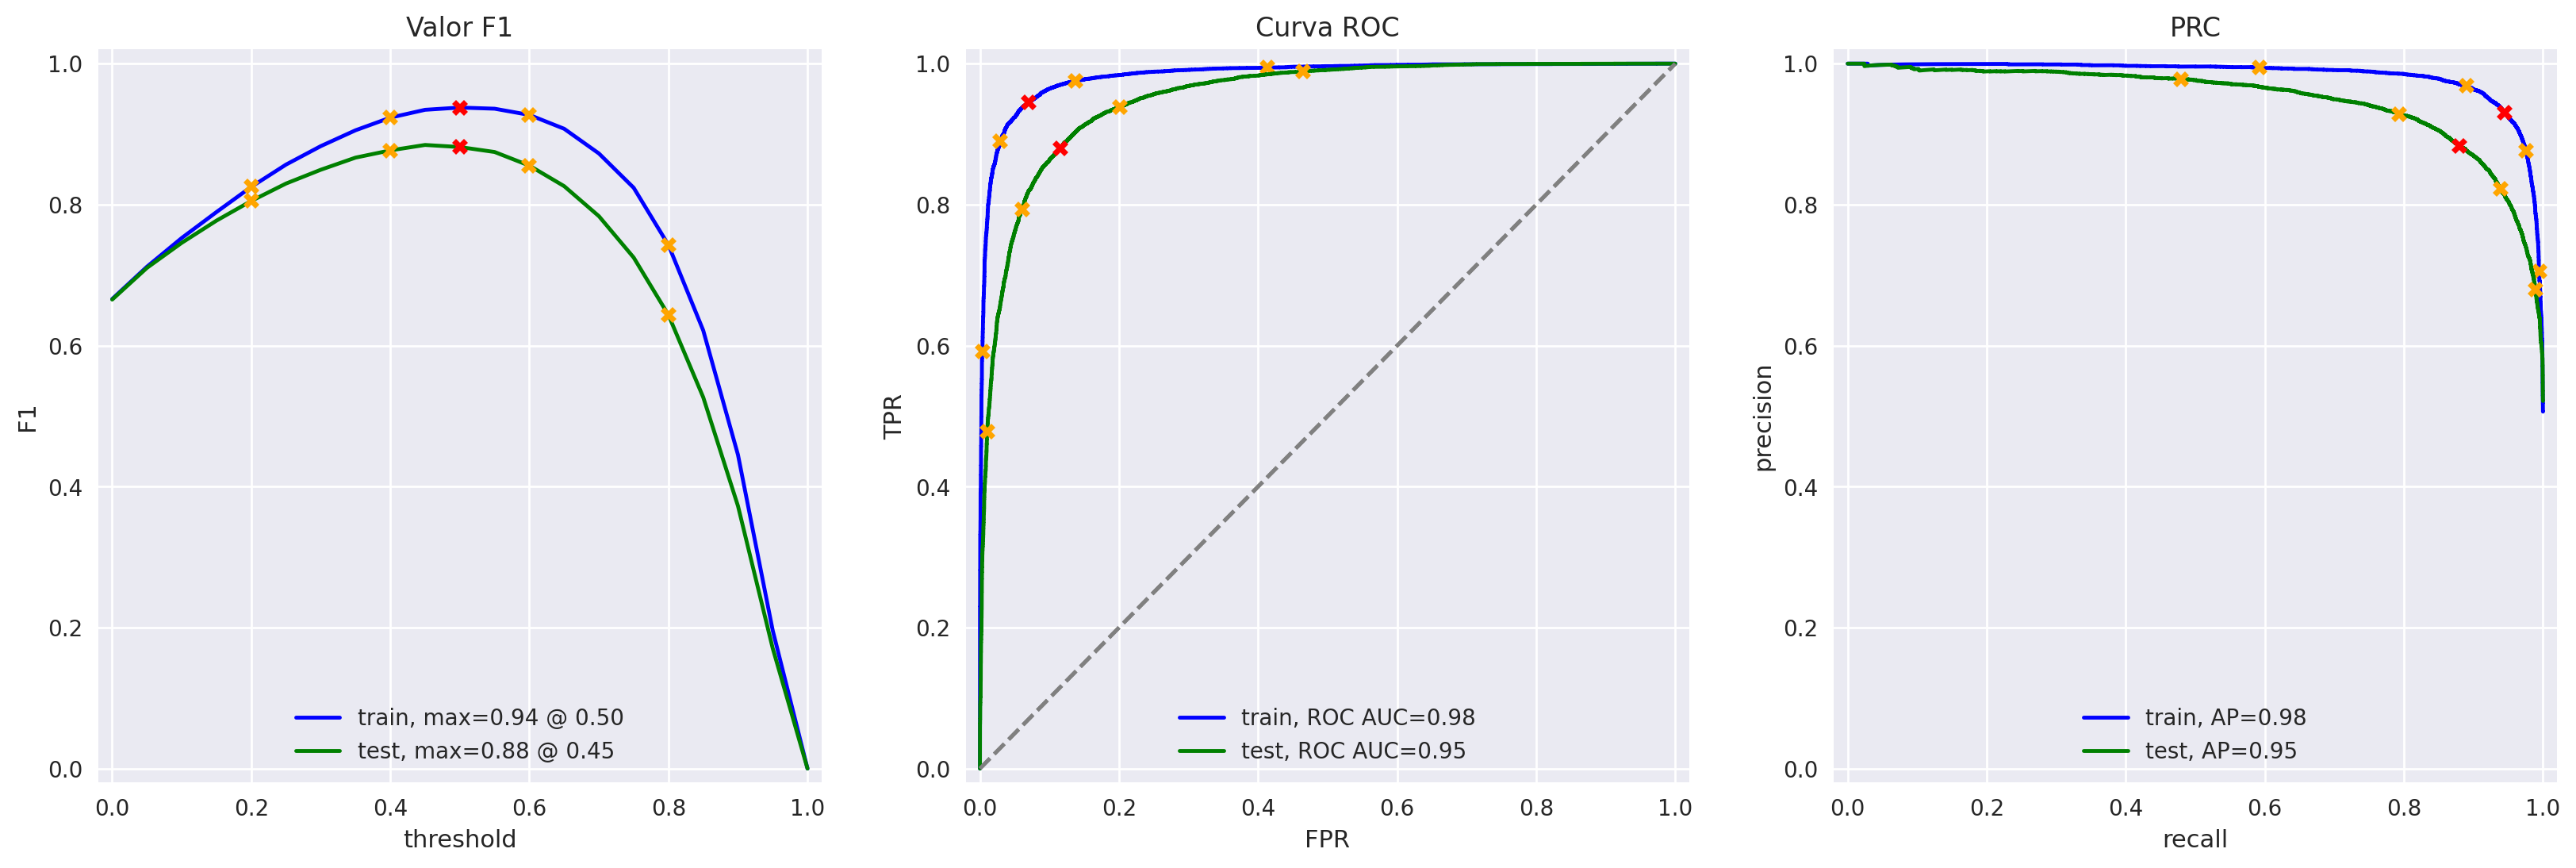

In [21]:
evaluate_model(model_1, train_features_1, train_target, test_features_1, test_target)

The TF-IDF + Logistic Regression classifier achieves a test F1 of approximately **0.88**, above the required 0.85, and a test ROC-AUC of approximately **0.95**. Its performance is substantially better than the baseline.

### 7.3 spaCy + TF-IDF + Logistic Regression

In [22]:
import spacy

nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])

In [23]:
def text_preprocessing_3(text):
    
    doc = nlp(text)
    tokens = [token.lemma_ for token in doc]
    
    return ' '.join(tokens)

In [24]:
# Preprocess text with spaCy
from tqdm.auto import tqdm

tqdm.pandas()

df_reviews_train['review_spacy'] = df_reviews_train['review_norm'].progress_apply(text_preprocessing_3)
df_reviews_test['review_spacy'] = df_reviews_test['review_norm'].progress_apply(text_preprocessing_3)

print('Treinamento:', df_reviews_train['review_spacy'].shape)
print('Teste:', df_reviews_test['review_spacy'].shape)

display(df_reviews_train[['review_norm', 'review_spacy']].head())

  0%|          | 0/23796 [00:00<?, ?it/s]

  0%|          | 0/23535 [00:00<?, ?it/s]

Treinamento: (23796,)
Teste: (23535,)


,review_norm,review_spacy
0,the pakage implies that warren beatty and gold...,the pakage imply that warren beatty and goldie...
1,how the hell did they get this made presenting...,how the hell do they get this make present its...
7,this true story of carlson s raiders is more o...,this true story of carlson s raider be more of...
8,should have been titled balderdash little in t...,should have be title balderdash little in the ...
9,the movie gung ho the story of carlson s makin...,the movie gung ho the story of carlson s makin...


In [25]:
# Vectorize lemmatized reviews with TF-IDF

count_tf_idf_3 = TfidfVectorizer(stop_words=list(stop_words))

train_features_3 = count_tf_idf_3.fit_transform(df_reviews_train['review_spacy'])
test_features_3 = count_tf_idf_3.transform(df_reviews_test['review_spacy'])

# Train Logistic Regression

model_3 = LogisticRegression(random_state=12345, max_iter=1000)

model_3.fit(train_features_3, train_target)

print('Training feature shape:', train_features_3.shape)
print('Test feature shape:', test_features_3.shape)

Dimensões do treinamento: (23796, 59156)
Dimensões do teste: (23535, 59156)


          train  test
Acurácia   0.93  0.88
F1         0.93  0.88
APS        0.98  0.95
ROC AUC    0.98  0.95


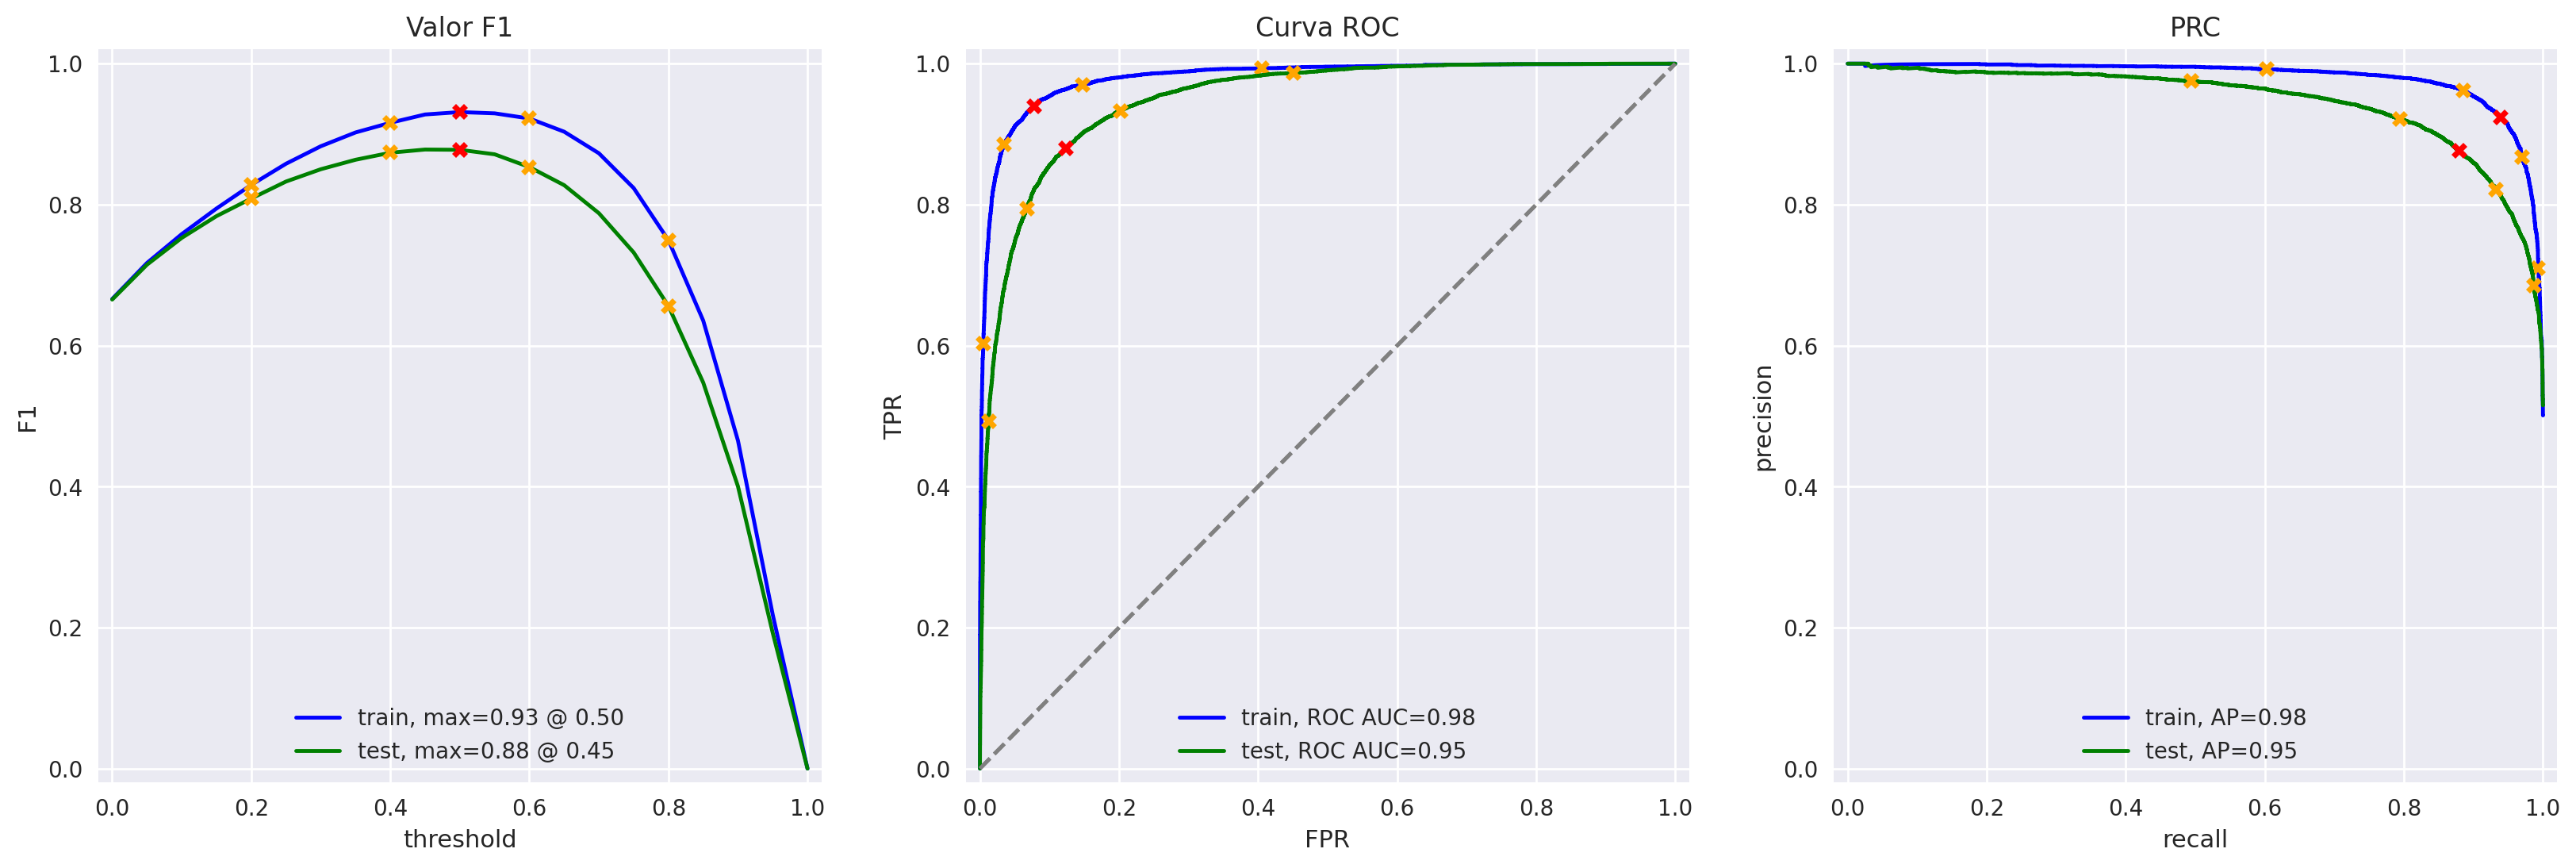

In [26]:
evaluate_model(model_3, train_features_3, train_target, test_features_3, test_target)

The spaCy-lemmatized TF-IDF classifier reaches approximately **0.88 test F1** and **0.95 test ROC-AUC**, meeting the project target. Lemmatization reduces vocabulary size while maintaining performance similar to the NLTK-based model.

### 7.4 spaCy + TF-IDF + LightGBM

In [27]:
from lightgbm import LGBMClassifier

In [28]:
# Train the LightGBM model

model_4 = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=10,
    random_state=12345,
    verbosity=-1,
    n_jobs=-1
)

model_4.fit(train_features_3, train_target)

print('LightGBM model trained successfully!')

Modelo 4 treinado com sucesso!


          train  test
Acurácia   0.90  0.84
F1         0.90  0.84
APS        0.97  0.92
ROC AUC    0.97  0.92


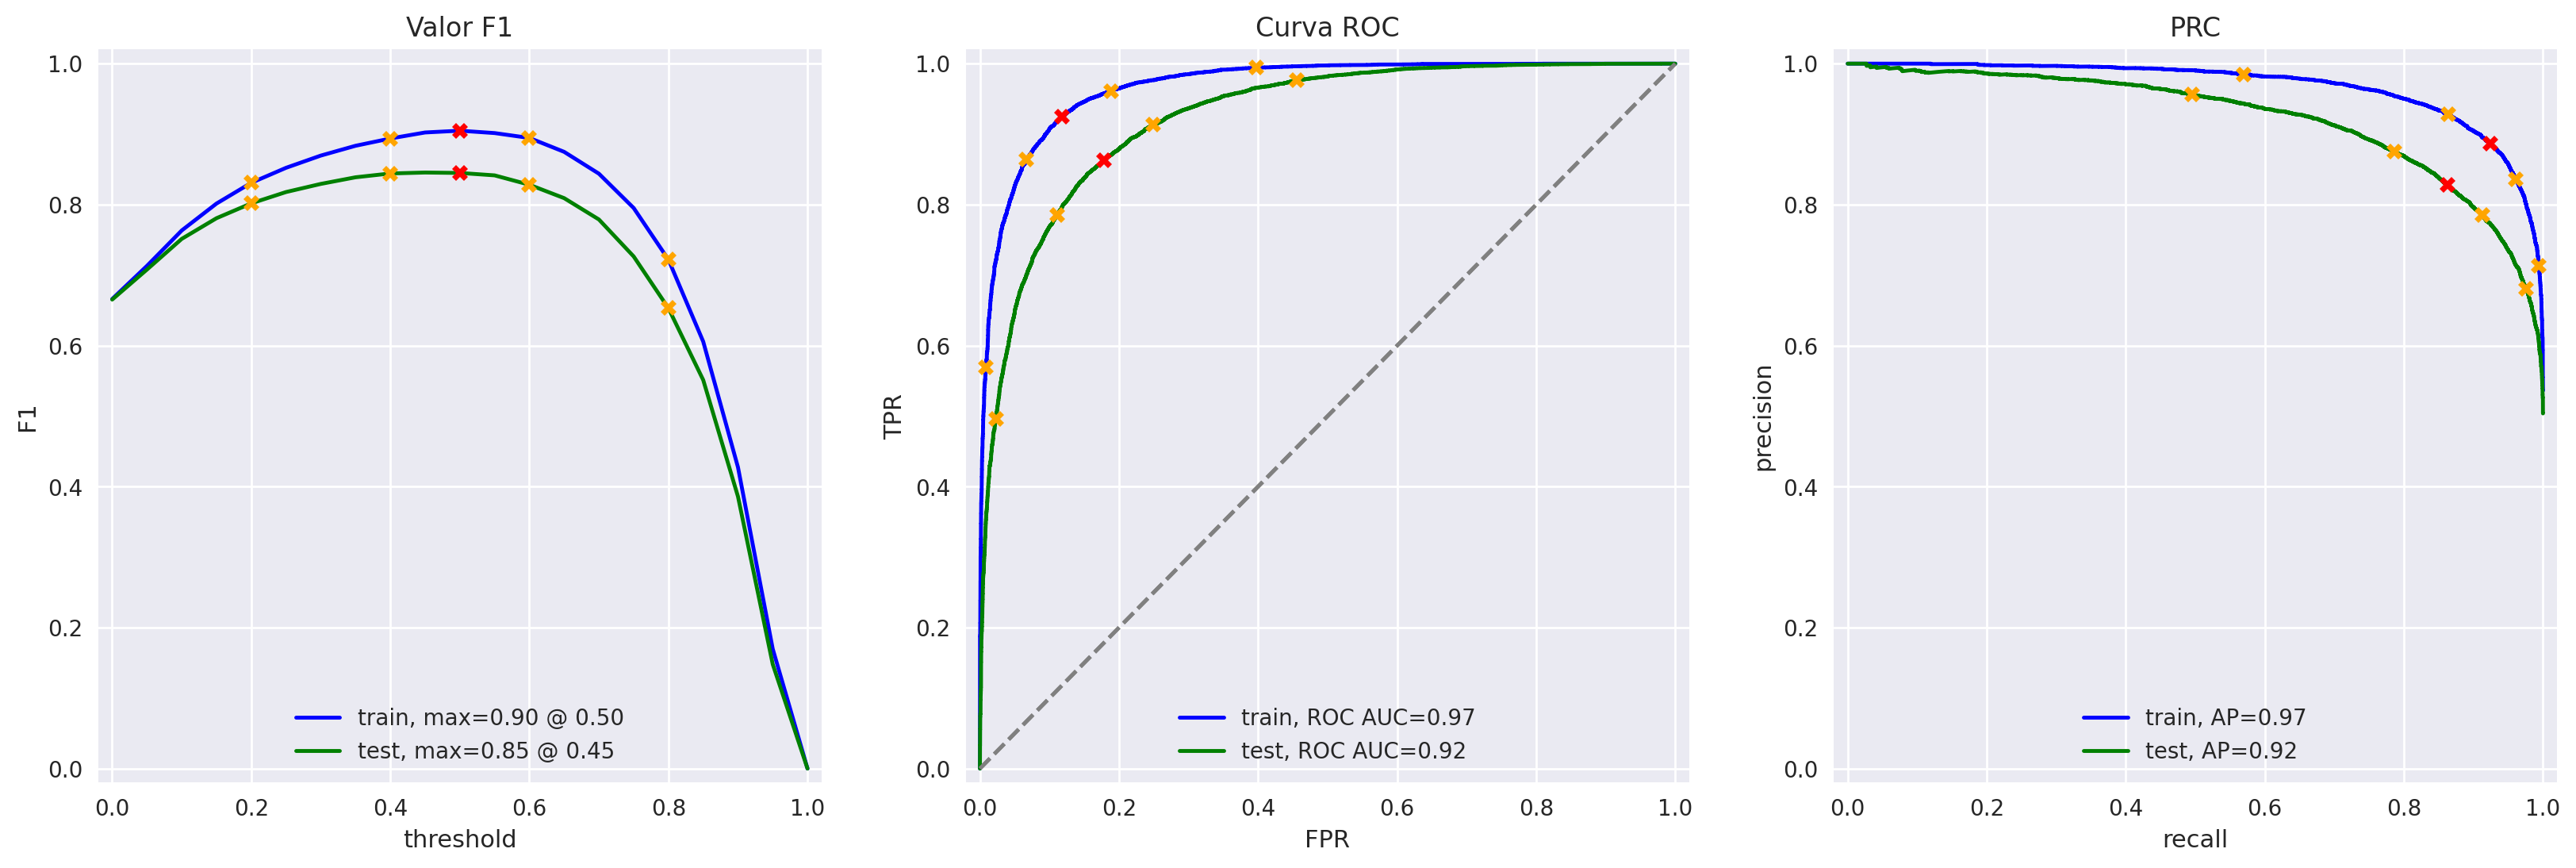

In [29]:
evaluate_model(
    model_4,
    train_features_3,
    train_target,
    test_features_3,
    test_target
)

LightGBM achieves approximately **0.84 test F1** and **0.92 test ROC-AUC**. It performs reasonably well but does not meet the 0.85 F1 requirement.

### 7.5 BERT Embeddings + Logistic Regression (Exploratory, 200 Reviews per Split)

In [30]:
import torch
import transformers

In [31]:
tokenizer = transformers.BertTokenizer.from_pretrained('bert-base-uncased')
config = transformers.BertConfig.from_pretrained('bert-base-uncased')
model = transformers.BertModel.from_pretrained('bert-base-uncased')

Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertModel: ['cls.seq_relationship.bias', 'cls.predictions.transform.dense.weight', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.bias', 'cls.predictions.transform.dense.bias', 'cls.seq_relationship.weight', 'cls.predictions.decoder.weight']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


In [32]:
def BERT_text_to_embeddings(texts, max_length=512, batch_size=100, force_device=None, disable_progress_bar=False):

    ids_list = []
    attention_mask_list = []

    # Token IDs padded with their attention masks

    for text in texts:
        ids = tokenizer.encode(text.lower(), add_special_tokens=True, truncation=True, max_length=max_length)
        padded = np.array(ids + [0] * (max_length - len(ids)))
        attention_mask = np.where(padded != 0, 1, 0)

        ids_list.append(padded)
        attention_mask_list.append(attention_mask)

    if force_device is not None:
        device = torch.device(force_device)
    else:
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    model.to(device)
    if not disable_progress_bar:
        print(f'Using device {device}.')

    # Generate embeddings in batches

    embeddings = []

    for i in tqdm(range(math.ceil(len(ids_list)/batch_size)), disable=disable_progress_bar):

        ids_batch = torch.LongTensor(ids_list[batch_size*i:batch_size*(i+1)]).to(device)
        attention_mask_batch = torch.LongTensor(attention_mask_list[batch_size*i:batch_size*(i+1)]).to(device)

        with torch.no_grad():            
            model.eval()
            batch_embeddings = model(input_ids=ids_batch, attention_mask=attention_mask_batch)   
        embeddings.append(batch_embeddings[0][:,0,:].detach().cpu().numpy())

    return np.concatenate(embeddings)

In [33]:
# BERT can be slow on CPU; use a limited 200-review sample
train_features_9 = BERT_text_to_embeddings(df_reviews_train['review_norm'].head(200), batch_size=8)

Usando o dispositivo cpu.


  0%|          | 0/25 [00:00<?, ?it/s]

/tmp/ipykernel_55/2853039448.py:31: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at  ../torch/csrc/utils/tensor_new.cpp:201.)
  ids_batch = torch.LongTensor(ids_list[batch_size*i:batch_size*(i+1)]).to(device)


In [34]:
print(df_reviews_train['review_norm'].shape)
print(train_features_9.shape)
print(train_target.shape)

(23796,)
(200, 768)
(23796,)


In [35]:
from sklearn.linear_model import LogisticRegression

# Match labels to the 200 sampled training reviews
train_target_9 = train_target.head(200)

# Train a classifier on BERT embeddings
model_9 = LogisticRegression(random_state=12345, max_iter=1000)

model_9.fit(train_features_9, train_target_9)

print('BERT classifier trained successfully!')
print('Feature shape:', train_features_9.shape)
print('Target shape:', train_target_9.shape)

Modelo 9 treinado com sucesso!
Dimensões das características: (200, 768)
Dimensões dos objetivos: (200,)


In [36]:
# Generate BERT embeddings for 200 test reviews

test_features_9 = BERT_text_to_embeddings(
    df_reviews_test['review_norm'].head(200),
    batch_size=8
)

test_target_9 = test_target.head(200)

print('Test feature shape:', test_features_9.shape)
print('Target shape:', test_target_9.shape)

Usando o dispositivo cpu.


  0%|          | 0/25 [00:00<?, ?it/s]

Dimensões do teste: (200, 768)
Dimensões dos objetivos: (200,)


          train  test
Acurácia    1.0  0.80
F1          1.0  0.77
APS         1.0  0.93
ROC AUC     1.0  0.90


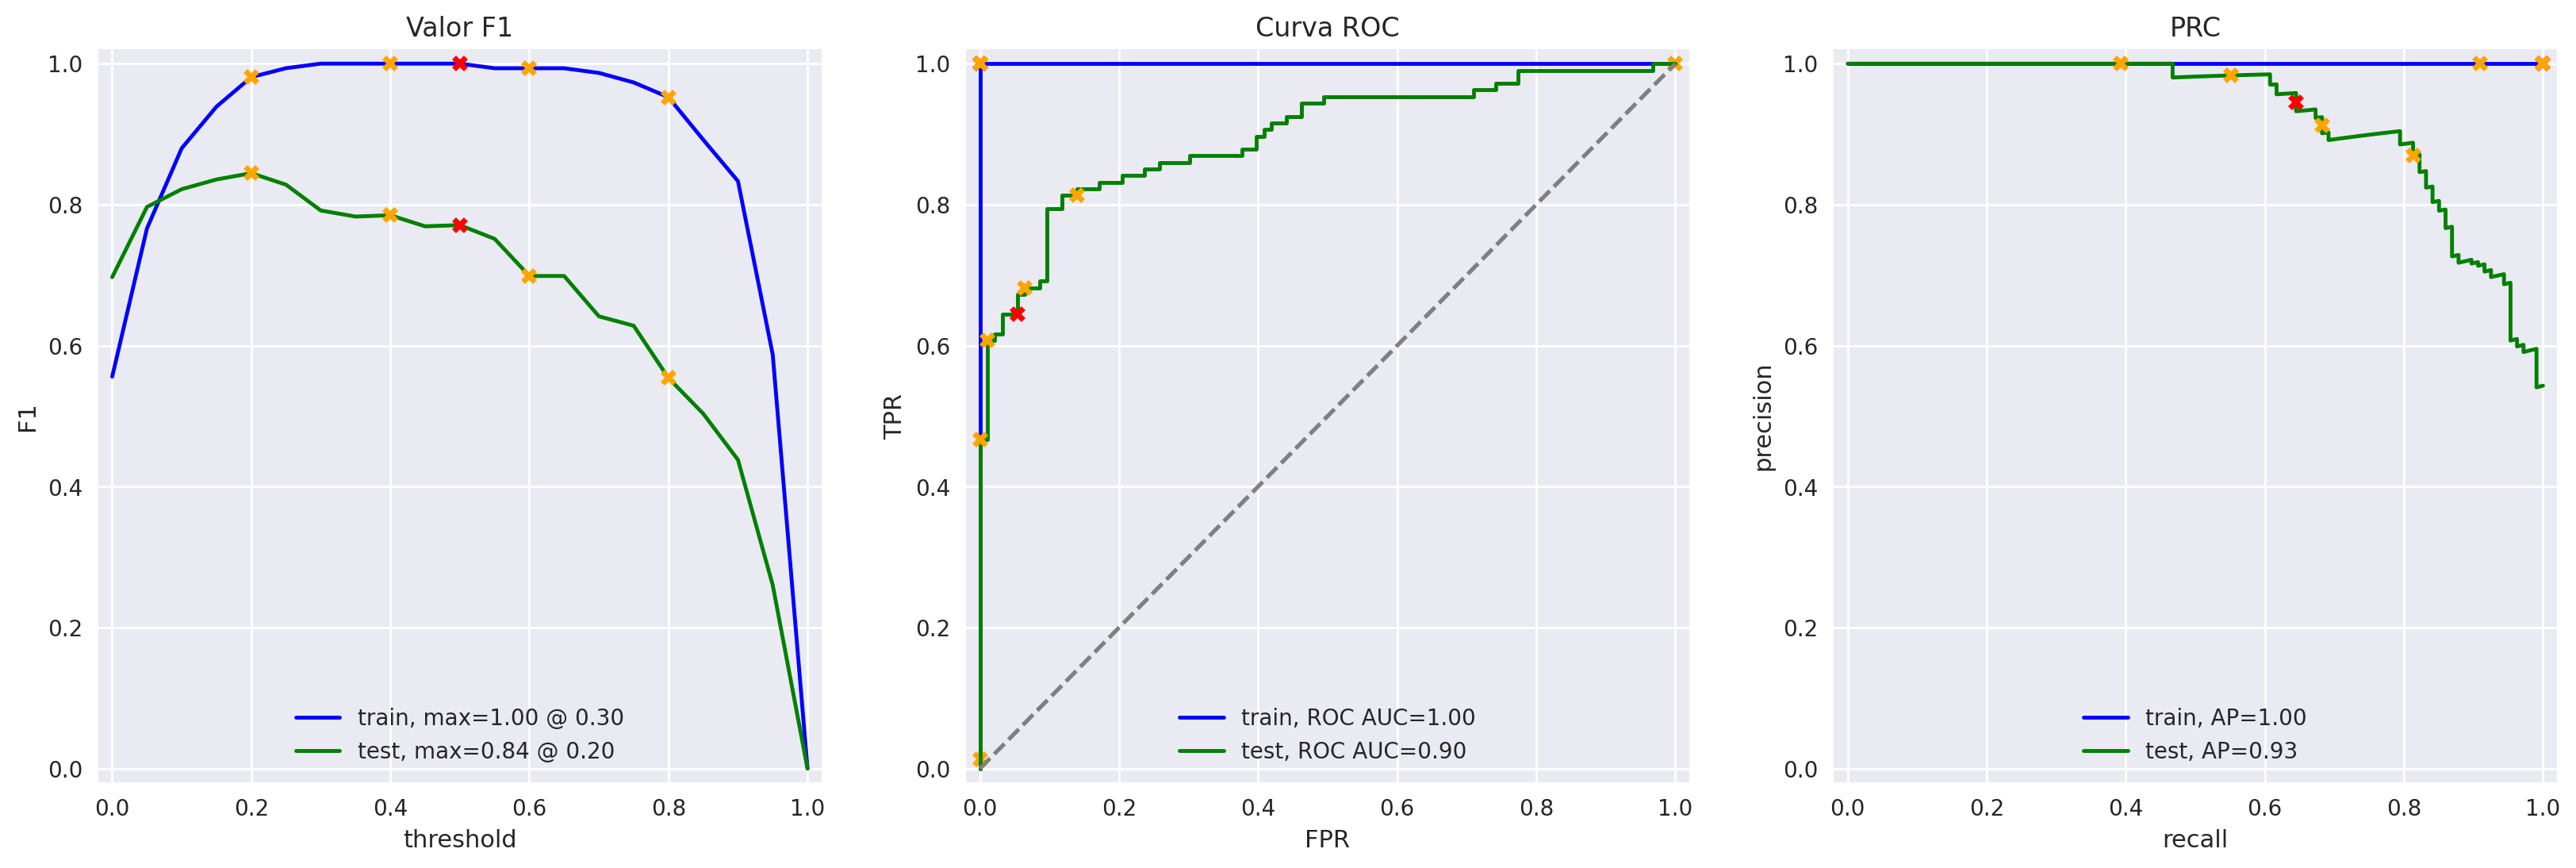

In [37]:
# Evaluate the BERT-based classifier

evaluate_model(
    model_9,
    train_features_9,
    train_target_9,
    test_features_9,
    test_target_9
)

The small-sample BERT experiment achieves approximately **0.77 test F1** and **0.90 test ROC-AUC**. The reported training F1 of 1.00 versus test F1 of 0.77 suggests overfitting. Because only 200 reviews from each partition were used, this experiment is not directly comparable to the full-data models.

## 8. Predictions on Custom Movie Reviews

In [39]:
# Custom English reviews for qualitative model testing

my_reviews = pd.DataFrame([
    "I really disliked this movie. The story was boring and the acting was terrible.",
    "The movie was so boring that I almost fell asleep halfway through.",
    "I absolutely loved this film. The acting was amazing and the story was fascinating.",
    "The actors looked tired and uninterested. The entire movie was disappointing.",
    "I did not expect this movie to be so good. It was a wonderful surprise.",
    "The movie has some flaws, but overall it is a decent and enjoyable film.",
    "What a masterpiece of bad filmmaking! I cannot believe I wasted two hours watching this.",
    "The new Netflix series was a pleasant surprise. I enjoyed every episode."
], columns=['review'])

my_reviews['review_norm'] = my_reviews['review'].apply(clean_text)

my_reviews

,review,review_norm
0,I really disliked this movie. The story was bo...,i really disliked this movie the story was bor...
1,The movie was so boring that I almost fell asl...,the movie was so boring that i almost fell asl...
2,I absolutely loved this film. The acting was a...,i absolutely loved this film the acting was am...
3,The actors looked tired and uninterested. The ...,the actors looked tired and uninterested the e...
4,I did not expect this movie to be so good. It ...,i did not expect this movie to be so good it w...
5,"The movie has some flaws, but overall it is a ...",the movie has some flaws but overall it is a d...
6,What a masterpiece of bad filmmaking! I cannot...,what a masterpiece of bad filmmaking i cannot ...
7,The new Netflix series was a pleasant surprise...,the new netflix series was a pleasant surprise...


In [40]:
# Classify custom reviews with the TF-IDF Logistic Regression model

my_features_1 = count_tf_idf.transform(my_reviews['review_norm'])

my_reviews['pred_model_1'] = model_1.predict(my_features_1)

my_reviews[['review', 'pred_model_1']]

,review,pred_model_1
0,I really disliked this movie. The story was bo...,0
1,The movie was so boring that I almost fell asl...,0
2,I absolutely loved this film. The acting was a...,1
3,The actors looked tired and uninterested. The ...,0
4,I did not expect this movie to be so good. It ...,1
5,"The movie has some flaws, but overall it is a ...",1
6,What a masterpiece of bad filmmaking! I cannot...,0
7,The new Netflix series was a pleasant surprise...,1


### 8.2 spaCy + Logistic Regression

In [41]:
texts = my_reviews['review_norm']

my_reviews_pred_prob = model_3.predict_proba(
    count_tf_idf_3.transform(
        texts.apply(lambda x: text_preprocessing_3(x))
    )
)[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}: {review}')

0.01: i really disliked this movie the story was boring and the acting was terrible
0.03: the movie was so boring that i almost fell asleep halfway through
0.98: i absolutely loved this film the acting was amazing and the story was fascinating
0.03: the actors looked tired and uninterested the entire movie was disappointing
0.99: i did not expect this movie to be so good it was a wonderful surprise
0.87: the movie has some flaws but overall it is a decent and enjoyable film
0.02: what a masterpiece of bad filmmaking i cannot believe i wasted two hours watching this
0.95: the new netflix series was a pleasant surprise i enjoyed every episode


### 8.3 spaCy + LightGBM

In [42]:
texts = my_reviews['review_norm']

tfidf_vectorizer_4 = count_tf_idf_3

my_reviews_pred_prob = model_4.predict_proba(
    tfidf_vectorizer_4.transform(
        texts.apply(lambda x: text_preprocessing_3(x))
    )
)[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}: {review}')

0.10: i really disliked this movie the story was boring and the acting was terrible
0.27: the movie was so boring that i almost fell asleep halfway through
0.92: i absolutely loved this film the acting was amazing and the story was fascinating
0.42: the actors looked tired and uninterested the entire movie was disappointing
0.90: i did not expect this movie to be so good it was a wonderful surprise
0.72: the movie has some flaws but overall it is a decent and enjoyable film
0.10: what a masterpiece of bad filmmaking i cannot believe i wasted two hours watching this
0.79: the new netflix series was a pleasant surprise i enjoyed every episode


### 8.4 BERT Embeddings + Logistic Regression

In [43]:
texts = my_reviews['review_norm']

my_reviews_features_9 = BERT_text_to_embeddings(texts, disable_progress_bar=True)

my_reviews_pred_prob = model_9.predict_proba(my_reviews_features_9)[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.00:  i really disliked this movie the story was boring and the acting was terrible
0.00:  the movie was so boring that i almost fell asleep halfway through
0.88:  i absolutely loved this film the acting was amazing and the story was fascinating
0.00:  the actors looked tired and uninterested the entire movie was disappointing
0.01:  i did not expect this movie to be so good it was a wonderful surprise
0.20:  the movie has some flaws but overall it is a decent and enjoyable film
0.00:  what a masterpiece of bad filmmaking i cannot believe i wasted two hours watching this
0.38:  the new netflix series was a pleasant surprise i enjoyed every episode


## 9. Conclusions

The goal was to classify IMDb movie reviews as positive or negative with a test F1 score of at least **0.85**.

The dataset includes **47,331 reviews** with approximately balanced sentiment labels (50.10% negative, 49.90% positive). The existing train/test split was retained, and no class-balancing technique was required.

**Reported test results from the original notebook:**

| Approach | Test F1 | Test ROC-AUC |
|---|---:|---:|
| Constant baseline | 0.00 | 0.50 |
| NLTK + TF-IDF + Logistic Regression | **0.88** | **0.95** |
| spaCy + TF-IDF + Logistic Regression | **0.88** | **0.95** |
| spaCy + TF-IDF + LightGBM | 0.84 | 0.92 |
| BERT embeddings + Logistic Regression (200 samples per split) | 0.77 | 0.90 |

Both TF-IDF + Logistic Regression variants exceed the target. spaCy lemmatization achieves comparable performance with a smaller vocabulary. The LightGBM model falls slightly short of the required F1.

The BERT experiment is exploratory: training on only 200 reviews leads to an apparent generalization gap, so its performance should not be interpreted as a fair full-dataset benchmark.

The custom-written English review examples reveal differences between model predictions, particularly on ambiguous or ironic wording. This qualitative exercise complements, but does not replace, the held-out test evaluation.

**Recommendation:** Of the evaluated approaches, TF-IDF + Logistic Regression is a strong and computationally efficient candidate for automated movie-review sentiment classification.

*The metrics and visualizations above are retained from the original notebook execution; they were not regenerated during this portfolio cleanup.*